# Study 2: reward-mode behavior with refined EDI observations

This notebook replays the existing refined-observation Q-tables for local, global, and mixed rewards. It does not train agents or change the environment. The replay uses the same five training seeds and twenty evaluation seeds recorded for Notebook 18.

The analysis compares development and mitigation actions, pollution over time, cumulative spending, and cross-region behavior.

## Verify state binning

`value_bin` assigns a value to the count of boundaries it meets or exceeds. Check just-below, exact, and just-above values for every boundary set used in the observation: EDI, currency, normalized pollutant load, and global GPI. Then verify one complete observation tuple.

In [27]:
from math import inf, nextafter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from study_2_economic_sustainability.config import EnvironmentConfig, TrainingConfig
from study_2_economic_sustainability.environment import ACTION_NAMES, ACTION_SPECS, EconomicSustainabilityEnvironment, value_bin
from study_2_economic_sustainability.train import load_q_tables

In [28]:
BOUNDARY_SETS = {
    "EDI": (34, 67, 70, 80, 90, 100),
    "currency": (200, 500),
    "normalized_pollutant_load": (0.33, 0.67),
    "global_GPI": (34, 67),
}

In [29]:
failures = []

for variable, boundaries in BOUNDARY_SETS.items():
    values = [-1.0]

    for boundary in boundaries:
        values.append(nextafter(boundary, -inf))
        values.append(boundary)
        values.append(nextafter(boundary, inf))

    values.append(boundaries[-1] + 1.0)

    for value in values:
        expected_bin = 0
        for boundary in boundaries:
            if value >= boundary:
                expected_bin += 1
        actual_bin = value_bin(value, boundaries)

        if actual_bin != expected_bin:
            failures.append((variable, value, expected_bin, actual_bin))

if failures:
    print("Boundary checks failed:")
    for variable, value, expected, actual in failures:
        print(f"{variable}: value={value}, expected={expected}, actual={actual}")
else:
    print("All value_bin boundary checks passed.")

All value_bin boundary checks passed.


In [30]:
config = EnvironmentConfig()
config.edi_observation_boundaries = BOUNDARY_SETS["EDI"]

environment = EconomicSustainabilityEnvironment(config=config)
environment.reset(7)

environment.development_indices = (90, 90, 90, 90)
environment.currency_balances = (500, 500, 500, 500)

environment.pollutant_loads = {
    "air": (67.0, 0.0, 0.0, 0.0),
    "water": (33.0, 0.0, 0.0, 0.0),
    "soil": (0.0, 0.0, 0.0, 0.0),
    "noise": (0.0, 0.0, 0.0, 0.0),
}

environment._update_indices()
environment.global_pollution_index = 67.0

observation = environment._observations()[0]
expected_observation = (5, 2, 2, 1, 0, 0, 2)

if observation == expected_observation:
    print("Environment observation boundary check passed.")
else:
    print("Environment observation boundary check failed.")
    print("Expected:", expected_observation)

print("Observed state tuple:", observation)

Environment observation boundary check passed.
Observed state tuple: (5, 2, 2, 1, 0, 0, 2)


## Replay the saved policies

The saved Q-tables choose actions greedily. For each transition, record regional development and investment choices, pollution loads, GPI, and spending. Summaries first average evaluation episodes within each training seed, then report variation across the five training seeds.

In [31]:
REWARD_MODES = ('local', 'global', 'mixed')
RESULTS_DIRECTORY = '../results/edi_resolution'
TRAINING_RESULTS = f'{RESULTS_DIRECTORY}/q_tables_notebook18.json'
trajectory_file = f'{RESULTS_DIRECTORY}/reward_mode_trajectories.csv'

In [32]:
environment_config = EnvironmentConfig()
environment_config.edi_observation_boundaries = BOUNDARY_SETS['EDI']
training_config = TrainingConfig()
trained_policies = load_q_tables(REWARD_MODES, training_config.training_seeds, training_config, RESULTS_DIRECTORY, notebook_number=18)

In [33]:
def calculate_action_statistics(actions, edi_before, info, regions):
    development_count = 0
    valid_development_count = 0
    prevention_count = 0
    cleanup_count = 0
    no_investment_count = 0

    decisions_above_70 = 0
    development_above_70 = 0
    valid_development_above_70 = 0

    development_choices = []

    for region in regions:
        action = actions[region]
        development, investment = ACTION_SPECS[action]
        valid = info["valid_actions"][region]
        edi = edi_before[region]

        development_choices.append(development)
        development_count += development

        if development == 1 and valid:
            valid_development_count += 1

        if investment in (1, 2, 3):
            prevention_count += 1

        elif investment in (4, 5, 6):
            cleanup_count += 1

        elif investment == 0:
            no_investment_count += 1

        if edi > 70:
            decisions_above_70 += 1

            if development == 1:
                development_above_70 += 1

                if valid:
                    valid_development_above_70 += 1

    count = len(actions)

    return {
        "development_actions": development_count,
        "development_fraction": development_count / count,
        "valid_development_actions": valid_development_count,
        "prevention_actions": prevention_count,
        "prevention_fraction": prevention_count / count,
        "cleanup_actions": cleanup_count,
        "cleanup_fraction": cleanup_count / count,
        "no_investment_actions": no_investment_count,
        "no_investment_fraction": no_investment_count / count,
        "development_decisions_above_70": development_above_70,
        "valid_development_actions_above_70": valid_development_above_70,
        "decisions_above_70": decisions_above_70,
        "same_joint_action": len(set(actions)) == 1,
        "same_development_choice": len(set(development_choices)) == 1,
    }

In [34]:
def calculate_trajectory_metrics(actions, edi_before, info, environment):
    metrics = {}
    regions = environment.config.regions

    edi_bands = (("70_79", 70, 80), ("80_89", 80, 90), ("90_99", 90, 100))

    for band, low, high in edi_bands:
        band_regions = []

        for region in regions:
            if low <= edi_before[region] < high:
                band_regions.append(region)

        development_count = 0

        for region in band_regions:
            action = actions[region]

            if ACTION_SPECS[action][0] == 1:
                development_count += 1

        metrics[f"decisions_{band}"] = len(band_regions)
        metrics[f"development_actions_{band}"] = development_count

    for pollutant in environment.config.pollutants:
        loads = info["pollutant_loads"][pollutant]

        metrics[f"mean_{pollutant}"] = np.mean(loads)
        metrics[f"spread_{pollutant}"] = max(loads) - min(loads)

    for action_id, action_name in enumerate(ACTION_NAMES):
        action_count = 0
        action_count_above_70 = 0

        for region in regions:
            if actions[region] == action_id:
                action_count += 1

                if edi_before[region] > 70:
                    action_count_above_70 += 1

        metrics[f"action_count_{action_id}"] = action_count
        metrics[f"action_count_above_70_{action_id}"] = action_count_above_70

    return metrics

In [42]:
trajectory_rows = []

for reward_mode in REWARD_MODES:
    for training_seed in training_config.training_seeds:
        agents = trained_policies[(reward_mode, training_seed)]
        environment = EconomicSustainabilityEnvironment(reward_mode, environment_config, reward_formula="candidate")

        for evaluation_seed in training_config.evaluation_seeds:
            observations = environment.reset(evaluation_seed)
            cumulative_mitigation_spending = 0.0
            cumulative_development_spending = 0.0

            while True:
                edi_before = environment.development_indices
                actions = []

                for region in environment.config.regions:
                    action = agents[region].select_action(observations[region], greedy=True)
                    actions.append(action)

                actions = tuple(actions)
                next_observations, _, terminated, truncated, info = environment.step(actions)

                prevention_spending = sum(info["prevention_costs_paid"])
                cleanup_spending = sum(info["cleanup_costs_paid"])
                mitigation_spending = prevention_spending + cleanup_spending
                development_spending = sum(info["development_costs_paid"])

                cumulative_mitigation_spending += mitigation_spending
                cumulative_development_spending += development_spending

                action_stats = calculate_action_statistics(actions, edi_before, info, environment.config.regions)
                trajectory_metrics = calculate_trajectory_metrics(actions, edi_before, info, environment)

                row = {
                    "reward_mode": reward_mode,
                    "training_seed": training_seed,
                    "evaluation_seed": evaluation_seed,
                    "step": environment.step_count,
                    "mean_edi": np.mean(info["development_indices"]),
                    "min_edi":min(info["development_indices"]),
                    "mean_gpi": info["global_pollution_index"],
                    "regional_gpi_spread": np.std(info["regional_pollution_indices"]),
                    "prevention_spending": prevention_spending,
                    "cleanup_spending": cleanup_spending,
                    "mitigation_spending": mitigation_spending,
                    "development_spending": development_spending,
                    "cumulative_mitigation_spending": cumulative_mitigation_spending,
                    "cumulative_development_spending": cumulative_development_spending,
                }

                row.update(action_stats)
                row.update(trajectory_metrics)

                trajectory_rows.append(row)
                observations = next_observations

                if terminated or truncated:
                    break

In [43]:
trajectories = pd.DataFrame(trajectory_rows)
trajectories.to_csv(trajectory_file, index=False)

trajectory_summary = trajectories.groupby("reward_mode").agg(
    evaluation_steps=("step", "size"),
    mean_gpi=("mean_gpi", "mean")
)

display(trajectory_summary.round(3))

,evaluation_steps,mean_gpi
reward_mode,,
global,20000,9.021
local,20000,14.854
mixed,20000,12.231


In [44]:
episode_metrics = trajectories.groupby(["reward_mode", "training_seed", "evaluation_seed"], sort=False).agg(
    final_mean_edi=("mean_edi", "last"),
    final_min_edi=("min_edi", "last"),
    mean_gpi=("mean_gpi", "mean"),
    mitigation_spending=("mitigation_spending", "sum")
).reset_index()

episode_metrics["all_regions_at_100"] = episode_metrics["final_min_edi"] >= 100
display(episode_metrics.round(3))

,reward_mode,training_seed,evaluation_seed,final_mean_edi,final_min_edi,mean_gpi,mitigation_spending,all_regions_at_100
0,local,11,200000,100.0,100,13.238,20520.0,True
1,local,11,200001,100.0,100,12.463,22140.0,True
2,local,11,200002,100.0,100,11.845,22415.0,True
3,local,11,200003,100.0,100,12.673,21825.0,True
4,local,11,200004,100.0,100,12.670,21255.0,True
...,...,...,...,...,...,...,...,...
295,mixed,53,200015,100.0,100,9.237,23080.0,True
296,mixed,53,200016,100.0,100,10.241,21975.0,True
297,mixed,53,200017,100.0,100,9.553,22615.0,True
298,mixed,53,200018,100.0,100,10.369,21375.0,True


In [45]:
metrics = ["final_mean_edi", "mean_gpi", "mitigation_spending", "all_regions_at_100"]
seed_metrics = episode_metrics.groupby(["reward_mode", "training_seed"], sort=False)[metrics].mean().reset_index()
replay_summary = seed_metrics.groupby("reward_mode", sort=False)[metrics].agg(["mean", "std"])

display(replay_summary.round(3))

final_mean_edi        mean_gpi        mitigation_spending  \
                      mean    std     mean    std                mean   
reward_mode                                                             
local               99.708  0.654   14.854  2.009            18425.70   
global              98.605  1.666    9.021  4.247            28064.85   
mixed               99.995  0.011   12.231  3.316            19904.45   

                      all_regions_at_100         
                  std               mean    std  
reward_mode                                      
local        2270.164               0.97  0.067  
global       8267.977               0.72  0.416  
mixed        3542.848               0.99  0.022

## Action frequencies, spending, and cross-region patterns

Action percentages use regional decisions as the denominator. Development can occur in the same action as prevention or cleanup, so those categories are not mutually exclusive. The joint-action agreement rate measures how often all four regions choose the identical action on a step; it is descriptive and does not imply that the agents communicate.

In [46]:
action_rows = []

for (reward_mode, training_seed), group in trajectories.groupby(["reward_mode", "training_seed"], sort=False):
    decisions = len(group) * len(environment_config.regions)
    above_70_decisions = group["decisions_above_70"].sum()

    development_above_70 = np.nan
    valid_development_above_70 = np.nan

    if above_70_decisions > 0:
        development_above_70 = group["development_decisions_above_70"].sum() / above_70_decisions
        valid_development_above_70 = group["valid_development_actions_above_70"].sum() / above_70_decisions

    row = {
        "reward_mode": reward_mode,
        "training_seed": training_seed,
        "development_frequency": group["development_actions"].sum() / decisions,
        "valid_development_frequency": group["valid_development_actions"].sum() / decisions,
        "prevention_frequency": group["prevention_actions"].sum() / decisions,
        "cleanup_frequency": group["cleanup_actions"].sum() / decisions,
        "no_investment_frequency": group["no_investment_actions"].sum() / decisions,
        "development_frequency_above_70": development_above_70,
        "valid_development_frequency_above_70": valid_development_above_70,
        "same_joint_action_rate": group["same_joint_action"].mean(),
        "same_development_choice_rate": group["same_development_choice"].mean(),
        "mean_regional_gpi_spread": group["regional_gpi_spread"].mean(),
        "prevention_spending": group["prevention_spending"].sum() / len(training_config.evaluation_seeds),
        "cleanup_spending": group["cleanup_spending"].sum() / len(training_config.evaluation_seeds),
        "total_mitigation_spending": group["mitigation_spending"].sum() / len(training_config.evaluation_seeds),
        "development_spending": group["development_spending"].sum() / len(training_config.evaluation_seeds),
    }

    for band in ("70_79", "80_89", "90_99"):
        band_decisions = group[f"decisions_{band}"].sum()
        frequency = np.nan

        if band_decisions > 0:
            frequency = group[f"development_actions_{band}"].sum() / band_decisions

        row[f"development_frequency_{band}"] = frequency

    action_rows.append(row)

action_by_seed = pd.DataFrame(action_rows)
action_by_seed.to_csv(f"{RESULTS_DIRECTORY}/reward_mode_action_frequencies.csv", index=False)

In [47]:
action_columns = ["development_frequency", "valid_development_frequency", "prevention_frequency", "cleanup_frequency", "no_investment_frequency", "development_frequency_above_70", "valid_development_frequency_above_70", "development_frequency_70_79", "development_frequency_80_89", "development_frequency_90_99", "same_joint_action_rate", "same_development_choice_rate", "mean_regional_gpi_spread", "prevention_spending", "cleanup_spending", "total_mitigation_spending", "development_spending"]

action_summary = action_by_seed.groupby("reward_mode", sort=False)[action_columns].agg(["mean", "std"])

action_summary.to_csv(f"{RESULTS_DIRECTORY}/reward_mode_action_summary.csv")

display(action_summary.round(3))

development_frequency        valid_development_frequency         \
                             mean    std                        mean    std   
reward_mode                                                                   
local                       0.124  0.002                       0.124  0.002   
global                      0.124  0.007                       0.122  0.003   
mixed                       0.125  0.000                       0.125  0.000   

            prevention_frequency        cleanup_frequency         \
                            mean    std              mean    std   
reward_mode                                                        
local                      0.216  0.144             0.611  0.148   
global                     0.292  0.072             0.632  0.078   
mixed                      0.137  0.146             0.748  0.126   

            no_investment_frequency         ... mean_regional_gpi_spread  \
                               mean    std  ...                     mean   
reward_mode                                 ...                            
local                         0.174  0.134  ...                    3.098   
global                        0.077  0.014  ...                    2.913   
mixed                         0.114  0.066  ...                    2.588   

                   prevention_spending           cleanup_spending            \
               std                mean       std             mean       std   
reward_mode                                                                   
local        1.199             3663.15  3034.634         14762.55  2655.439   
global       0.982             6337.15  3481.462         21727.70  5076.332   
mixed        0.504             2435.90  2959.037         17468.55  4263.917   

            total_mitigation_spending           development_spending           
                                 mean       std                 mean      std  
reward_mode                                                                    
local                        18425.70  2270.164               9943.0  127.456  
global                       28064.85  8267.977               9766.0  261.185  
mixed                        19904.45  3542.848               9999.0    2.236  

[3 rows x 34 columns]

In [48]:
action_frequency_rows = []

for (reward_mode, training_seed), group in trajectories.groupby(["reward_mode", "training_seed"], sort=False):
    decisions = len(group) * len(environment_config.regions)
    above_70_decisions = group["decisions_above_70"].sum()

    for action_id, action_name in enumerate(ACTION_NAMES):
        overall_frequency = group[f"action_count_{action_id}"].sum() / decisions
        frequency_above_70 = np.nan

        if above_70_decisions > 0:
            frequency_above_70 = group[f"action_count_above_70_{action_id}"].sum() / above_70_decisions

        row = {
            "reward_mode": reward_mode,
            "training_seed": training_seed,
            "action": action_name,
            "overall_frequency": overall_frequency,
            "frequency_above_70": frequency_above_70,
        }

        action_frequency_rows.append(row)

action_frequency_by_seed = pd.DataFrame(action_frequency_rows)
action_frequency_by_seed.to_csv(f"{RESULTS_DIRECTORY}/reward_mode_action_name_frequencies.csv", index=False)

action_frequency_summary = action_frequency_by_seed.groupby(["reward_mode", "action"], sort=False)[["overall_frequency", "frequency_above_70"]].agg(["mean", "std"])

display(action_frequency_summary.round(3))

overall_frequency         \
                                                 mean    std   
reward_mode action                                             
local       maintain_none                       0.155  0.135   
            develop_none                        0.019  0.007   
            maintain_prevent_low                0.104  0.078   
            maintain_prevent_medium             0.044  0.081   
            maintain_prevent_high               0.042  0.069   
            maintain_clean_low                  0.286  0.143   
            maintain_clean_medium               0.193  0.144   
            maintain_clean_high                 0.052  0.054   
            develop_prevent_low                 0.022  0.011   
            develop_prevent_medium              0.002  0.003   
            develop_prevent_high                0.002  0.003   
            develop_clean_low                   0.045  0.009   
            develop_clean_medium                0.030  0.008   
            develop_clean_high                  0.005  0.002   
global      maintain_none                       0.064  0.009   
            develop_none                        0.012  0.008   
            maintain_prevent_low                0.074  0.050   
            maintain_prevent_medium             0.094  0.087   
            maintain_prevent_high               0.072  0.094   
            maintain_clean_low                  0.226  0.199   
            maintain_clean_medium               0.142  0.162   
            maintain_clean_high                 0.204  0.138   
            develop_prevent_low                 0.020  0.013   
            develop_prevent_medium              0.020  0.015   
            develop_prevent_high                0.012  0.010   
            develop_clean_low                   0.028  0.008   
            develop_clean_medium                0.017  0.008   
            develop_clean_high                  0.015  0.011   
mixed       maintain_none                       0.086  0.063   
            develop_none                        0.028  0.014   
            maintain_prevent_low                0.012  0.008   
            maintain_prevent_medium             0.103  0.144   
            maintain_prevent_high               0.000  0.000   
            maintain_clean_low                  0.304  0.140   
            maintain_clean_medium               0.364  0.176   
            maintain_clean_high                 0.006  0.013   
            develop_prevent_low                 0.015  0.013   
            develop_prevent_medium              0.007  0.009   
            develop_prevent_high                0.001  0.001   
            develop_clean_low                   0.039  0.014   
            develop_clean_medium                0.029  0.014   
            develop_clean_high                  0.006  0.005   

                                    frequency_above_70         
                                                  mean    std  
reward_mode action                                             
local       maintain_none                        0.115  0.154  
            develop_none                         0.003  0.004  
            maintain_prevent_low                 0.116  0.088  
            maintain_prevent_medium              0.049  0.091  
            maintain_prevent_high                0.047  0.077  
            maintain_clean_low                   0.318  0.163  
            maintain_clean_medium                0.219  0.166  
            maintain_clean_high                  0.059  0.061  
            develop_prevent_low                  0.007  0.003  
            develop_prevent_medium               0.000  0.000  
            develop_prevent_high                 0.001  0.003  
            develop_clean_low                    0.030  0.004  
            develop_clean_medium                 0.033  0.009  
            develop_clean_high                   0.004  0.004  
global      maintain_none                        0.035  0.018  
   

In [49]:
trajectory_by_seed = trajectories.groupby(["reward_mode", "training_seed", "step"], sort=False).mean(numeric_only=True).reset_index()
trajectory_columns = ["mean_edi", "mean_gpi", "regional_gpi_spread", "cumulative_mitigation_spending", "cumulative_development_spending", "mean_air", "mean_water", "mean_soil", "mean_noise"]
trajectory_summary = trajectory_by_seed.groupby(["reward_mode", "step"], sort=False)[trajectory_columns].agg(["mean", "std"])

trajectory_summary.to_csv(f"{RESULTS_DIRECTORY}/reward_mode_trajectory_summary.csv")

In [50]:
checkpoint_steps = (20, 50, 100, 150, 200)
checkpoints = trajectory_by_seed[trajectory_by_seed["step"].isin(checkpoint_steps)]
spending_columns = ["cumulative_mitigation_spending", "cumulative_development_spending"]
spending_checkpoints = checkpoints.groupby(["reward_mode", "step"], sort=False)[spending_columns].agg(["mean", "std"])

spending_checkpoints.to_csv(f"{RESULTS_DIRECTORY}/reward_mode_spending_checkpoints.csv")
display(spending_checkpoints.round(1))

cumulative_mitigation_spending          \
                                           mean     std   
reward_mode step                                          
local       20                            566.4    41.3   
            50                           2864.2   144.4   
            100                          7986.9   753.7   
            150                         13192.8  1468.0   
            200                         18425.7  2270.2   
global      20                           1193.0   199.9   
            50                           3756.8   481.2   
            100                         10958.4  1960.8   
            150                         19468.6  5145.7   
            200                         28064.8  8268.0   
mixed       20                            659.0    59.8   
            50                           2846.0   101.6   
            100                          8374.2  1057.4   
            150                         14140.6  2287.7   
            200                         19904.4  3542.8   

                 cumulative_development_spending         
                                            mean    std  
reward_mode step                                         
local       20                            4112.0   45.4  
            50                            8894.0  126.4  
            100                           9940.0  128.6  
            150                           9943.0  127.5  
            200                           9943.0  127.5  
global      20                            3408.0  256.7  
            50                            7536.0  521.1  
            100                           9743.0  287.9  
            150                           9766.0  261.2  
            200                           9766.0  261.2  
mixed       20                            3980.0   86.0  
            50                            8887.0   95.4  
            100                           9999.0    2.2  
            150                           9999.0    2.2  
            200                           9999.0    2.2

## Trajectories over the 200-step episode

Lines show the mean trajectory after averaging evaluation episodes within training seed; shaded regions show one standard deviation across the five training seeds. The GPI and pollutant panels show whether lower overall pollution comes from broad reductions or a change in particular pollutant stocks.

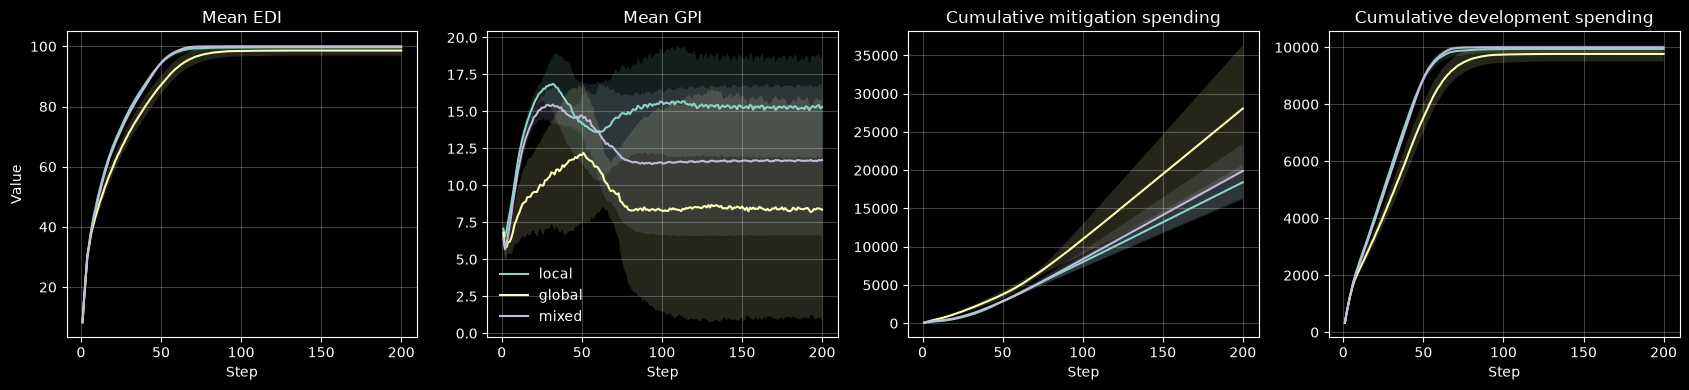

In [51]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))

plot_columns = (("mean_edi", "Mean EDI"), ("mean_gpi", "Mean GPI"), ("cumulative_mitigation_spending", "Cumulative mitigation spending"), ("cumulative_development_spending", "Cumulative development spending"))

for axis, (column, title) in zip(axes, plot_columns):
    for reward_mode in REWARD_MODES:
        summary = trajectory_summary.loc[reward_mode]

        steps = summary.index.to_numpy()
        mean = summary[(column, "mean")].to_numpy()
        spread = summary[(column, "std")].fillna(0).to_numpy()

        axis.plot(steps, mean, label=reward_mode)
        axis.fill_between(steps, mean - spread, mean + spread, alpha=0.15)

    axis.set_title(title)
    axis.set_xlabel("Step")
    axis.grid(alpha=0.25)

axes[0].set_ylabel("Value")
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

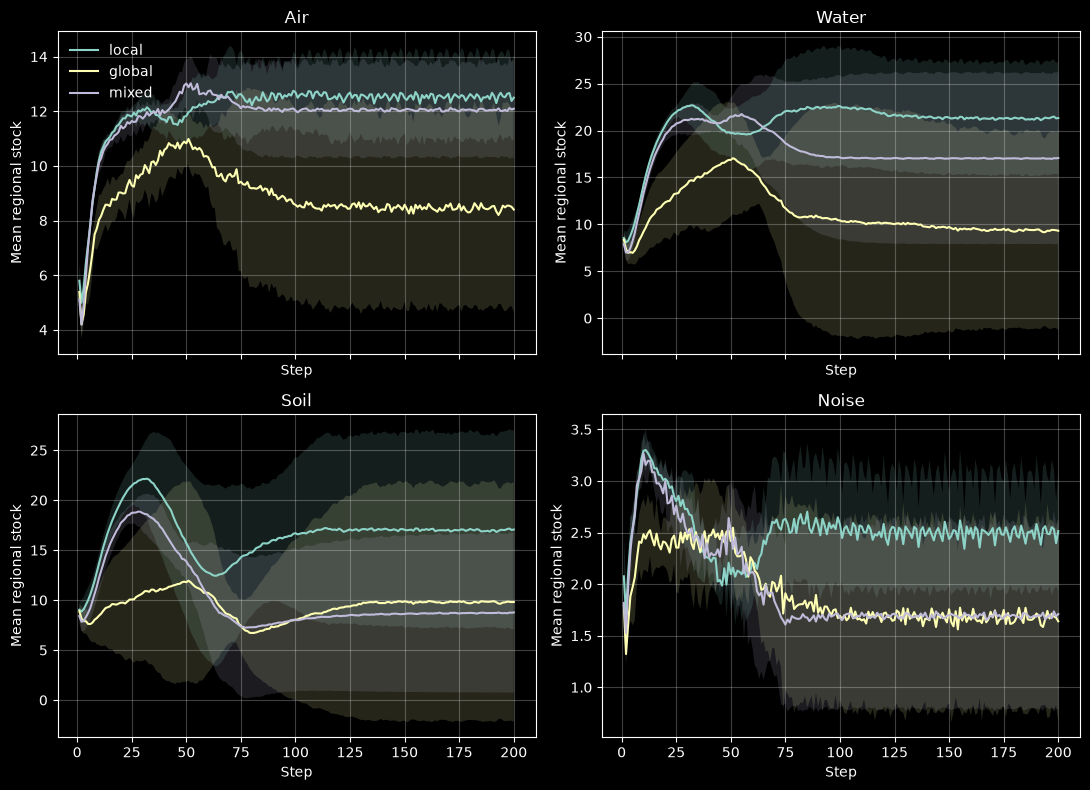

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True)

for axis, pollutant in zip(axes.flat, ("air", "water", "soil", "noise")):
    column = f"mean_{pollutant}"

    for reward_mode in REWARD_MODES:
        summary = trajectory_summary.loc[reward_mode]

        steps = summary.index.to_numpy()
        mean = summary[(column, "mean")].to_numpy()
        spread = summary[(column, "std")].fillna(0).to_numpy()

        axis.plot(steps, mean, label=reward_mode)
        axis.fill_between(steps, mean - spread, mean + spread, alpha=0.15)

    axis.set_title(pollutant.title())
    axis.set_xlabel("Step")
    axis.set_ylabel("Mean regional stock")
    axis.grid(alpha=0.25)

axes[0, 0].legend(frameon=False)

plt.tight_layout()
plt.show()

## Findings

The `value_bin` checks passed for all four observation variables: EDI, currency, normalized pollutant stock, and global GPI. Values exactly on a boundary move to the higher bin, and the complete refined observation tuple matched the expected bins.

Global reward achieved the lowest mean GPI (9.02), alongside the highest mitigation spending (28,065 per evaluation episode). It used prevention in 29.2% and cleanup in 63.2% of regional decisions, and selected no mitigation in 7.7%. Local reward spent 18,426 on mitigation and had mean GPI 14.85; it chose no mitigation in 17.4% of decisions. Mixed reward spent 19,904, had mean GPI 12.23, and used cleanup most often (74.8%) while prevention was least common (13.7%). These frequencies describe chosen actions; spending uses costs actually paid.

The timing helps explain the development difference. By step 50, global policies had spent about 3,757 on mitigation and 7,536 on development, compared with 2,864 and 8,894 for local and 2,846 and 8,887 for mixed. Global policies front-loaded more mitigation and developed more slowly. By step 100, the development spending totals were closer (9,743 global, 9,940 local, 9,999 mixed), while global mitigation spending remained higher. This is consistent with global reward lowering pollution through stronger early prevention and more high-level cleanup, while the 70% local component in mixed reward preserves a stronger development incentive.

All modes continued to develop above EDI 70 at similar rates: valid development actions were about 7.8% of above-70 decisions for local, 7.9% for mixed, and 7.9% for global. Mixed reached all-region EDI 100 in 99 of 100 evaluation episodes, versus 97 local and 72 global. Global's lower pollution therefore comes with slower or less consistent completion of development, while mixed keeps development high at a moderate pollution and spending level.

The behavior suggests an incentive tradeoff, but it is not direct action coordination. All four regions chose the identical joint action in only 0.3% of global, 0.8% of local, and 1.3% of mixed steps. Their develop-versus-maintain choices agreed more often (72-75%). Mixed had the smallest mean regional GPI spread (2.59, compared with 2.91 global and 3.10 local), even though global had the lowest average GPI. A shared reward changes the value signal; agents still select actions independently from local observations.

## Moderate emissions stress test

Replay the same saved policies and evaluation seeds with both baseline and EDI-linked emissions increased by 20%. All other coefficients, reward calculations, observations, and actions remain fixed. This is a robustness check of the existing policies, not a new training condition.

In [53]:
from copy import deepcopy
from study_2_economic_sustainability.evaluation import run_episode

In [54]:
EMISSION_MULTIPLIER = 1.20

stress_config = deepcopy(environment_config)

for pollutant, value in stress_config.baseline_emissions.items():
    stress_config.baseline_emissions[pollutant] = value * EMISSION_MULTIPLIER

for pollutant, value in stress_config.edi_emissions_per_point.items():
    stress_config.edi_emissions_per_point[pollutant] = value * EMISSION_MULTIPLIER

baseline_results = pd.read_csv(f"{RESULTS_DIRECTORY}/matched_evaluation_episodes.csv")
baseline_results = baseline_results[baseline_results["condition"] == "refined"].copy()

print(f"Emissions multiplier: {EMISSION_MULTIPLIER}")
print(f"Baseline episodes available: {len(baseline_results)}")

Emissions multiplier: 1.2
Baseline episodes available: 300


In [55]:
def analyze_stress_episode(transitions, environment, terminated, reward_mode, training_seed, evaluation_seed):
    prevention_spending = 0.0
    cleanup_spending = 0.0
    development_spending = 0.0
    development_decisions_above_70 = 0
    decisions_above_70 = 0
    gross_emissions_total = 0.0
    remaining_emissions_total = 0.0
    peak_pressure = 0.0

    failure_pollutants = set()
    gpi_values = []
    trajectory_rows = []

    cumulative_mitigation_spending = 0.0
    cumulative_development_spending = 0.0

    for transition in transitions:
        info = transition["info"]

        prevention_this_step = sum(info["prevention_costs_paid"])
        cleanup_this_step = sum(info["cleanup_costs_paid"])
        development_this_step = sum(info["development_costs_paid"])

        prevention_spending += prevention_this_step
        cleanup_spending += cleanup_this_step
        development_spending += development_this_step

        cumulative_mitigation_spending += prevention_this_step + cleanup_this_step
        cumulative_development_spending += development_this_step

        gpi_values.append(info["global_pollution_index"])

        for pollutant in stress_config.pollutants:
            gross_emissions_total += sum(info["gross_emissions"][pollutant])
            remaining_emissions_total += sum(info["remaining_emissions"][pollutant])

            for region in stress_config.regions:
                load = info["pollutant_loads"][pollutant][region]
                limit = stress_config.pollution_limits[pollutant]
                pressure = load / limit

                peak_pressure = max(peak_pressure, pressure)

        for region in stress_config.regions:
            edi = transition["development_before"][region]

            if edi > 70:
                decisions_above_70 += 1

                action = transition["actions"][region]
                development = ACTION_SPECS[action][0]

                if development == 1:
                    development_decisions_above_70 += 1

        if transition["terminated"]:
            for region, pollutant in info["failed_regions"]:
                failure_pollutants.add(pollutant)

        trajectory_row = {
            "reward_mode": reward_mode,
            "training_seed": training_seed,
            "evaluation_seed": evaluation_seed,
            "step": transition["step"],
            "mean_edi": np.mean(info["development_indices"]),
            "min_edi": min(info["development_indices"]),
            "mean_gpi": info["global_pollution_index"],
            "prevention_spending": prevention_this_step,
            "cleanup_spending": cleanup_this_step,
            "mitigation_spending": prevention_this_step + cleanup_this_step,
            "development_spending": development_this_step,
            "cumulative_mitigation_spending": cumulative_mitigation_spending,
            "cumulative_development_spending": cumulative_development_spending,
        }

        trajectory_rows.append(trajectory_row)

    failure_step = np.nan
    development_frequency_above_70 = np.nan

    if terminated:
        failure_step = environment.step_count

    if decisions_above_70 > 0:
        development_frequency_above_70 = development_decisions_above_70 / decisions_above_70

    episode_row = {
        "reward_mode": reward_mode,
        "training_seed": training_seed,
        "evaluation_seed": evaluation_seed,
        "emission_multiplier": EMISSION_MULTIPLIER,
        "steps": len(transitions),
        "failure": terminated,
        "failure_step": failure_step,
        "failure_pollutants": ", ".join(sorted(failure_pollutants)),
        "final_mean_edi": np.mean(environment.development_indices),
        "all_regions_at_100": min(environment.development_indices) == 100,
        "mean_gpi": np.mean(gpi_values),
        "prevention_spending": prevention_spending,
        "cleanup_spending": cleanup_spending,
        "mitigation_spending": prevention_spending + cleanup_spending,
        "development_spending": development_spending,
        "development_frequency_above_70": development_frequency_above_70,
        "gross_emissions_total": gross_emissions_total,
        "remaining_emissions_total": remaining_emissions_total,
        "peak_pollutant_pressure": peak_pressure,
    }

    return episode_row, trajectory_rows

In [56]:
stress_episode_rows = []
stress_trajectory_rows = []

for reward_mode in REWARD_MODES:
    for training_seed in training_config.training_seeds:
        agents = trained_policies[(reward_mode, training_seed)]
        environment = EconomicSustainabilityEnvironment(reward_mode, stress_config, reward_formula="candidate")

        for evaluation_seed in training_config.evaluation_seeds:
            transitions, terminated, truncated = run_episode(environment, agents, evaluation_seed)

            episode_row, trajectory_rows = analyze_stress_episode(transitions, environment, terminated, reward_mode, training_seed, evaluation_seed)

            stress_episode_rows.append(episode_row)
            stress_trajectory_rows.extend(trajectory_rows)

stress_episodes = pd.DataFrame(stress_episode_rows)
stress_trajectories = pd.DataFrame(stress_trajectory_rows)

stress_episodes["mitigation_per_step"] = stress_episodes["mitigation_spending"] / stress_episodes["steps"]

stress_episodes.to_csv(f"{RESULTS_DIRECTORY}/emissions_plus_20pct_evaluation.csv", index=False)
stress_trajectories.to_csv(f"{RESULTS_DIRECTORY}/emissions_plus_20pct_trajectories.csv", index=False)

print(f"Evaluated episodes: {len(stress_episodes)}")
print(f"Recorded trajectory steps: {len(stress_trajectories)}")

Evaluated episodes: 300
Recorded trajectory steps: 37553


In [57]:
comparison_columns = ["failure", "all_regions_at_100", "final_mean_edi", "mean_gpi", "mitigation_spending", "development_spending", "development_frequency_above_70"]
matching_columns = ["reward_mode", "training_seed", "evaluation_seed"]

available_columns = matching_columns.copy()

for column in comparison_columns:
    if column in baseline_results.columns:
        available_columns.append(column)

baseline_for_pairing = baseline_results[available_columns].copy()

paired_episodes = baseline_for_pairing.merge(stress_episodes, on=matching_columns, suffixes=("_baseline", "_stress"), validate="one_to_one")

paired_metrics = []

metrics = ("final_mean_edi", "mean_gpi", "mitigation_spending", "development_spending", "development_frequency_above_70")

for metric in metrics:
    base_name = f"{metric}_baseline"
    stress_name = f"{metric}_stress"

    if base_name in paired_episodes.columns and stress_name in paired_episodes.columns:
        change_column = f"{metric}_change"

        paired_episodes[change_column] = paired_episodes[stress_name] - paired_episodes[base_name]
        paired_metrics.append(change_column)

paired_by_training_seed = paired_episodes.groupby(["reward_mode", "training_seed"], sort=False)[paired_metrics].mean().reset_index()
paired_by_training_seed.to_csv(f"{RESULTS_DIRECTORY}/emissions_plus_20pct_paired_changes.csv", index=False)
print(f"Matched episodes: {len(paired_episodes)}")

Matched episodes: 300


In [58]:
stress_summary = stress_episodes.groupby("reward_mode", sort=False).agg(
    episodes=("evaluation_seed", "size"),
    failure_rate=("failure", "mean"),
    mean_steps=("steps", "mean"),
    mean_failure_step=("failure_step", "mean"),
    all_regions_at_100_rate=("all_regions_at_100", "mean"),
    final_mean_edi=("final_mean_edi", "mean"),
    mean_gpi=("mean_gpi", "mean"),
    mitigation_spending=("mitigation_spending", "mean"),
    mitigation_per_step=("mitigation_per_step", "mean"),
    development_spending=("development_spending", "mean"),
    peak_pressure=("peak_pollutant_pressure", "mean")
).round(3)

display(stress_summary)

,episodes,failure_rate,mean_steps,mean_failure_step,all_regions_at_100_rate,final_mean_edi,mean_gpi,mitigation_spending,mitigation_per_step,development_spending,peak_pressure
reward_mode,,,,,,,,,,,
local,100,0.71,109.67,72.775,0.15,85.592,26.474,7176.60,47.098,7240.0,0.854
global,100,0.37,156.70,82.973,0.27,92.768,17.718,18061.15,98.173,8609.0,0.596
mixed,100,0.73,109.16,75.562,0.01,86.478,26.448,6409.75,44.417,7345.0,0.877


In [59]:
survivors = stress_episodes[~stress_episodes["failure"]]

survivor_summary = survivors.groupby("reward_mode", sort=False).agg(
    surviving_episodes=("evaluation_seed", "size"),
    final_mean_edi=("final_mean_edi", "mean"),
    all_regions_at_100=("all_regions_at_100", "mean"),
    mean_gpi=("mean_gpi", "mean"),
    mitigation_spending=("mitigation_spending", "mean")
).round(3)

display(survivor_summary)

,surviving_episodes,final_mean_edi,all_regions_at_100,mean_gpi,mitigation_spending
reward_mode,,,,,
local,29,96.259,0.517,21.058,19982.069
global,63,97.833,0.429,12.568,26654.524
mixed,27,94.685,0.037,21.536,17805.370


In [60]:
paired_summary = paired_by_training_seed.groupby("reward_mode", sort=False)[paired_metrics].agg(["mean", "std"])
paired_summary.to_csv(f"{RESULTS_DIRECTORY}/emissions_plus_20pct_paired_summary.csv")
display(paired_summary.round(3))

final_mean_edi_change        mean_gpi_change         \
                             mean    std            mean    std   
reward_mode                                                       
local                     -14.115  5.486          11.621  3.831   
global                     -5.838  7.467           8.697  7.728   
mixed                     -13.518  3.344          14.218  4.607   

            mitigation_spending_change             \
                                  mean        std   
reward_mode                                         
local                         -11249.1   6413.059   
global                        -10003.7  13905.329   
mixed                         -13494.7   6345.896   

            development_frequency_above_70_change         
                                             mean    std  
reward_mode                                               
local                                       0.027  0.019  
global                                      0.015  0.024  
mixed                                       0.029  0.017

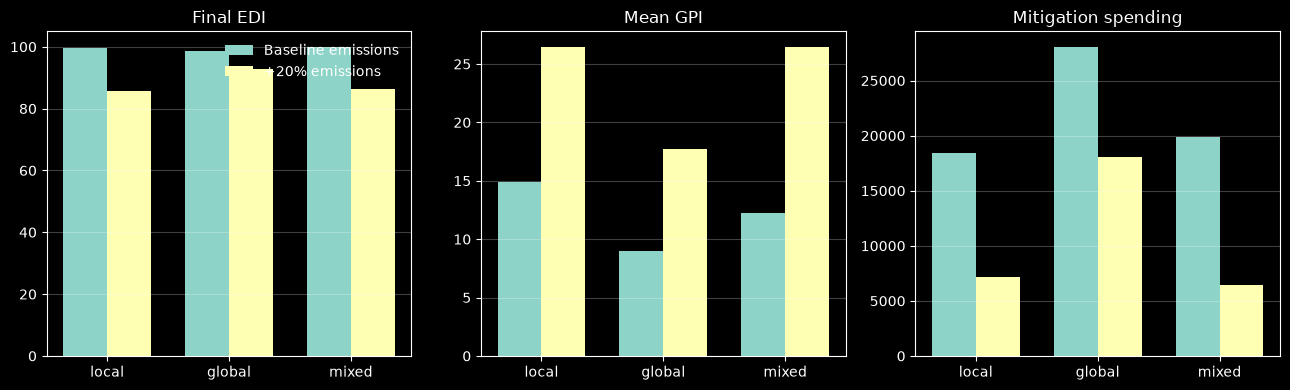

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

plot_metrics = (("final_mean_edi", "Final EDI"), ("mean_gpi", "Mean GPI"), ("mitigation_spending", "Mitigation spending"))

for axis, (metric, title) in zip(axes, plot_metrics):
    base_values = baseline_results.groupby("reward_mode")[metric].mean().reindex(REWARD_MODES)
    stress_values = stress_episodes.groupby("reward_mode")[metric].mean().reindex(REWARD_MODES)

    positions = np.arange(len(REWARD_MODES))

    axis.bar(positions - 0.18, base_values, width=0.36, label="Baseline emissions")
    axis.bar(positions + 0.18, stress_values, width=0.36, label="+20% emissions")

    axis.set_xticks(positions, REWARD_MODES)
    axis.set_title(title)
    axis.grid(axis="y", alpha=0.25)

axes[0].legend(frameon=False)

plt.tight_layout()
plt.show()

## Emissions stress findings

The 20% increase was a substantial stress for these policies. Across 300 matched episodes, 181 failed environmentally. Failure rates were 37% for global reward, 71% for local, and 73% for mixed. Every failure was triggered by soil reaching its limit. Global policies also ran longer on average (157 steps versus about 109 for local and mixed) and failed later when they did fail.

Mean final EDI fell from baseline values of 98.61 global, 99.71 local, and 100.00 mixed to 92.77, 85.59, and 86.48. Mean GPI rose from 9.02, 14.85, and 12.23 to 17.72, 26.47, and 26.45. All four regions still reached EDI 100 in 27% of global episodes, 15% of local episodes, and 1% of mixed episodes.

Global reward was the most robust in this stress test. It spent about 98 currency per step on mitigation on average, compared with 47 for local and 44 for mixed. Raw per-episode mitigation totals are lower under stress because failed episodes end early; among the surviving 200-step episodes, mean mitigation spending was about 26,655 global, 19,982 local, and 17,805 mixed. Treat the survivor-only comparison as conditional on survival.

The saved policies therefore differ in resilience: global reward sacrifices some development completion for substantially better pollution control and survival under higher emissions. The mixed reward's baseline EDI advantage largely disappears under this stress. No policy was retrained, and the 20% multiplier was applied only to baseline and EDI-linked emissions; reward, observation bins, recovery, spillover, costs, and thresholds stayed fixed.